# Deep hedging under transaction costs

ES 335 project, Param Tanna (24110236) and Pranav Magarde (24110269).

This notebook walks through the study in the order we actually did it. The heavy lifting lives in `src/`; here we call it, look at what comes out, and explain what we concluded at each step. Every number printed below is either computed live in this notebook or read from `results/`, the same files the project website draws from.

The question: we sell a 30-day at-the-money call on an index and hedge it once a day. Under a proportional transaction cost, which hedging policy gives the smallest tail loss (CVaR at 95% of terminal P&L, net of fees), and does a neural network trained on that objective rediscover the no-trade band that theory predicts?

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from IPython.display import Image, display
import data, engine, strategies as st, samplers as sp, simulators as sim, policy as pol
import experiments as ex
torch.set_num_threads(8)
pd.set_option('display.width', 140, 'display.precision', 4)
RES = os.path.join('..', 'results')
load = lambda f: json.load(open(os.path.join(RES, f)))
print('torch', torch.__version__, '| numpy', np.__version__)

torch 2.14.0+cpu | numpy 2.2.1


## 1. The data, and the two facts that decide everything

Daily history of the NIFTY 50 and the S&P 500 from Yahoo Finance. One row is one trading day; we use only the adjusted close. `data.fetch` caches the download in `data/raw/`, which is not committed (we do not redistribute the raw prices).

In [2]:
rep = load('data_report.json')
rows = ['rows_downloaded', 'duplicate_dates_dropped', 'nonpositive_or_missing_close_dropped',
        'rows_kept', 'first_date', 'last_date', 'adjclose_equals_close', 'zero_volume_days',
        'largest_gap_days', 'largest_gap_ends']
pd.DataFrame({i: [rep[i][r] for r in rows] for i in rep}, index=rows)

,NIFTY50,SP500
rows_downloaded,4731,6758
duplicate_dates_dropped,0,0
nonpositive_or_missing_close_dropped,31,0
rows_kept,4700,6758
first_date,2007-09-17,2000-01-03
last_date,2026-11-13,2026-11-13
adjclose_equals_close,True,True
zero_volume_days,1333,1
largest_gap_days,6,7
largest_gap_ends,2014-10-07,2001-09-17


NIFTY on Yahoo only starts in September 2007, not 2000 as our proposal assumed. The 31 dropped NIFTY rows are exchange holidays that come back as empty rows (one is 27 November 2008, the Mumbai attacks). The longest S&P gap ends on 17 September 2001, the post-9/11 closure; that return is real and stays in. Adjusted close equals close, so these are price indices with no dividends, which matches our zero-dividend model.

Now the statistics that matter. Plain geometric Brownian motion says daily log returns are independent normal draws. Excess kurtosis should then be 0, and squared returns should be uncorrelated.

In [3]:
facts = ['annualised_vol', 'skewness', 'excess_kurtosis', 'ljung_box_returns_20', 'ljung_box_abs_returns_20']
pd.DataFrame({(i, era): [rep[i][era][k] for k in facts] for i in rep for era in ('pre2019', 'post2019')},
             index=facts).round(3)

NIFTY50               SP500          
                           pre2019  post2019   pre2019  post2019
annualised_vol               0.224     0.174     0.192     0.194
skewness                     0.111    -1.423    -0.216    -0.673
excess_kurtosis             12.359    21.412     8.501    15.641
ljung_box_returns_20        59.749   104.605   120.292   293.021
ljung_box_abs_returns_20  3748.689  2051.307  7916.029  3079.824

Both assumptions fail badly. Kurtosis is 12 and 8.5 before 2019, and the Ljung-Box statistic on absolute returns is in the thousands against a 5% critical value of 31.4: calm days follow calm days, violent days follow violent ones. Note also that the test period (2019 on) is harsher than the training period: NIFTY's kurtosis jumps to 21. March 2020 lives in the test set.

## 2. The engine has to be right before anything else matters

There is one P&L engine and every strategy, learned or not, is scored by it. Before trusting a single comparison we run ten checks. Each one tests a property that must hold if the mathematics is implemented correctly.

In [4]:
import controls
assert controls.main() == 0

premium of the ATM 30-day call: 2.752417

1. delta vs finite difference   rel err 2.70e-10
   gamma vs finite difference   rel err 9.08e-08

2. zero cost: risk must fall monotonically as we rebalance more
   n=   5  CVaR95   -2.4260  sd  1.0098  mean  0.00331
   n=  10  CVaR95   -1.7270  sd  0.7334  mean  0.00510


   n=  30  CVaR95   -1.0063  sd  0.4323  mean  0.00413


   n=  60  CVaR95   -0.7052  sd  0.3086  mean  0.00295


   n= 120  CVaR95   -0.5062  sd  0.2196  mean -0.00046



3. zero cost: mean P&L = -0.00117, standard error 0.00096, |z| = 1.22

4. unhedged CVaR  -12.3970  vs  delta CVaR   -1.0032



5. band(width=0) vs bs_delta   max abs difference 0.00e+00
6. band(width=10) mean trades  0.0000 (must be 0)

7. same holdings, rising cost: fee paid must rise, P&L must fall


     0.0 bps  mean cost   0.0000  mean P&L   -0.0012
     5.0 bps  mean cost   0.1370  mean P&L   -0.1382
    20.0 bps  mean cost   0.5479  mean P&L   -0.5491


    50.0 bps  mean cost   1.3698  mean P&L   -1.3710

8. Leland sigma: k=0 -> 0.200000 (must equal 0.20), k=20bps -> 0.223904

9. Whalley-Wilmott at k=0 vs bs_delta   max abs diff 0.00e+00



10. causality: perturbing the future changes past holdings by
    bs_delta 0.00e+00   band 0.00e+00   (both must be 0)

ALL CONTROLS PASSED


Check 2 is the one we like most. At zero cost the hedging error should shrink like the square root of the rebalancing interval, so four times as many rebalances should halve the tail. From 30 to 120 rebalances the CVaR goes from about -1.006 to -0.506: a ratio of 1.99.

## 3. Episodes: one protocol for every data source

An episode is 60 trading days of history, then 30 days of hedging. At the sale the desk quotes the realised volatility of the history, prices the call with Black-Scholes and starts hedging. Real windows and simulated windows go through exactly the same code.

In [5]:
df, _ = data.clean(data.fetch('NIFTY50'))
real_test = sp.real(df, '2019-01-01')
print(real_test.S.shape[0], 'real NIFTY test episodes; first sold', real_test.dates[0], ', last', real_test.dates[-1])
print('quoted vol across them: median %.3f, 5%% %.3f, 95%% %.3f' % tuple(np.percentile(real_test.sigma_imp.numpy(), [50, 5, 95])))
print('every path starts at 100:', bool(torch.allclose(real_test.S[:, sp.HIST], torch.tensor(100., dtype=real_test.S.dtype))))

1910 real NIFTY test episodes; first sold 2019-01-02 , last 2026-09-29
quoted vol across them: median 0.134, 5% 0.082, 95% 0.231
every path starts at 100: True


## 4. The simulator we threw away

Training needs hundreds of thousands of episodes, and real history has a couple of hundred non-overlapping ones. So we fit a price generator on the training era. Our first Heston fit matched daily moments. It looked fine, and it was wrong for hedging: to first order a hedged option's P&L is driven by how far realised volatility strays from the quoted one, and the daily-moment fit made that surprise far too large. We refit on the statistic that actually matters, the distribution of realised over quoted volatility at the 30-day horizon.

In [6]:
cal_d, cal_h = load('heston_calibration.json'), load('heston_horizon_calibration.json')
pd.DataFrame({(i, fit): [c[i][k] for k in ('kappa', 'theta', 'xi', 'rho', 'feller_satisfied')]
              for i in cal_d for fit, c in (('daily fit', cal_d), ('horizon fit', cal_h))},
             index=['kappa', 'theta', 'xi', 'rho', 'Feller holds'])

NIFTY50                 SP500            
             daily fit horizon fit daily fit horizon fit
kappa          19.8601     15.1356   17.7655     15.0084
theta           0.0503      0.0503    0.0367      0.0367
xi              1.9925      0.7368    1.8817      0.9134
rho            -0.0022      -0.494   -0.7819     -0.8899
Feller holds     False        True     False        True

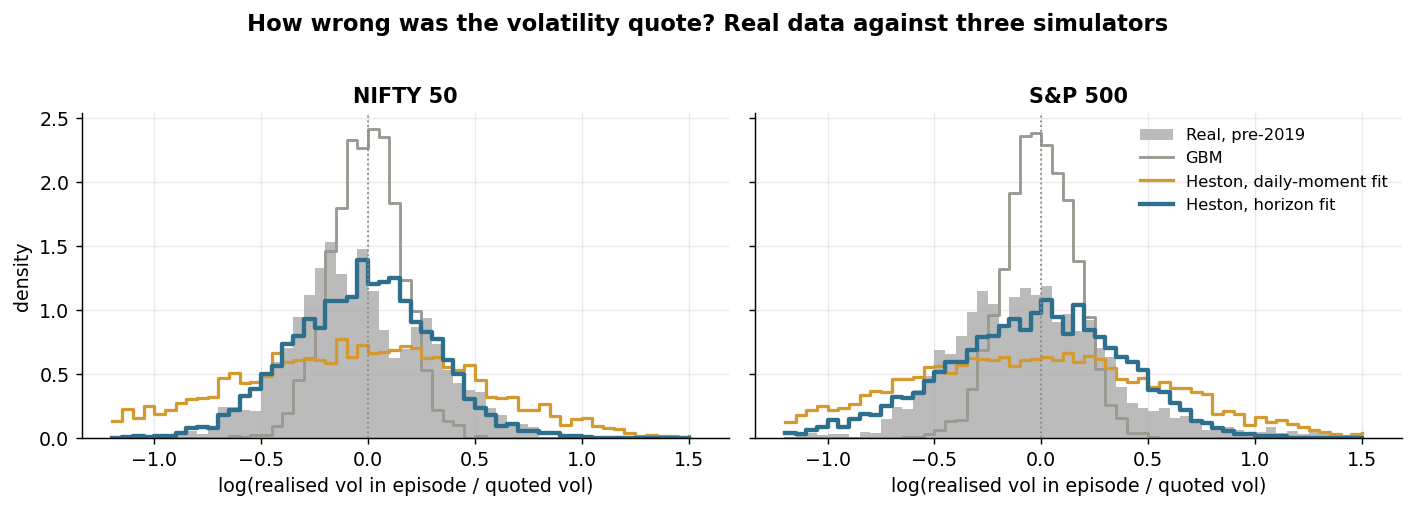

,heston,p95_heston,heston_daily,p95_heston_daily,real,p95_real
NIFTY50,-2.764,1.610,-5.209,2.404,-2.654,1.664
SP500,-2.501,1.838,-3.848,2.617,-2.486,1.905


In [7]:
display(Image(os.path.join(RES, 'figures', 'fig_surprise.png')))
chk = load('analysis.json')['extras']['sim_check']
pd.DataFrame(chk).T.round(3)

The last table is the check that convinced us. Delta hedging's tail loss was never a calibration target, yet under the horizon fit (`heston`) it lands within a few percent of the real training-era value (`real`), while the daily fit (`heston_daily`) roughly doubles it for NIFTY. This is still the calibration period, so we treat it as a sanity check, not evidence. The evidence is the 2019+ test.

## 5. Baselines, and one short training run

The rule-based strategies, weakest to strongest: unhedged, Black-Scholes delta, Leland delta, a constant no-trade band, and the Whalley-Wilmott band, whose width follows gamma and, in continuous trading, grows like cost^(1/3). The band width and the Whalley-Wilmott risk aversion were tuned on validation paths only.

In [8]:
tuned = load('tuned_rules.json')
pd.DataFrame(tuned['gbm']).T[['band_w', 'band_val_cvar', 'ww_gamma', 'ww_val_cvar']]

,band_w,band_val_cvar,ww_gamma,ww_val_cvar
0,0.005,-1.0808,0.1,-1.0802
5,0.02,-1.2504,100,-1.2379
10,0.03,-1.4216,100,-1.3925
20,0.03,-1.771,100,-1.6968
50,0.075,-2.7852,10,-2.5251


Whalley-Wilmott beats the constant band at every cost level: a width that adapts to gamma beats one fixed number. It is the real bar for the network.

Here is a deliberately short training run so you can watch the idea work: 120 iterations, nothing like the 1,500 the real models get. The network sees the state and its current holding; the loss is CVaR of the simulated P&L; the gradient goes back through all 30 decisions.

delta on this validation set: -1.394, demo network after 120 iterations: -1.280


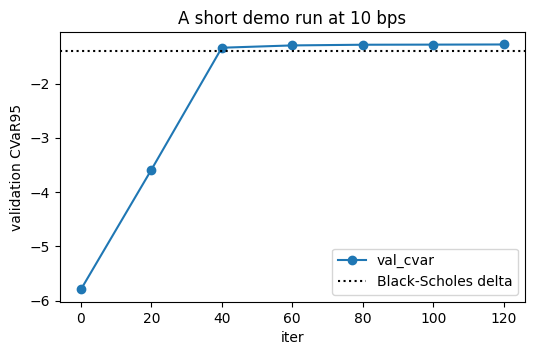

In [9]:
pool = ex.vol_pool()
val = sp.gbm(5000, np.random.default_rng(1001), sigma_pool=pool)
demo = pol.make_policy('mlp')
res = pol.train(demo, lambda n, rng: sp.gbm(n, rng, sigma_pool=pool), 10, val,
                iters=120, batch=4096, eval_every=20, seed=7, log=None)
h = pd.DataFrame(res['history'])
bs_val = float(engine.cvar(ex.score(ex.rule_holdings('bs_delta', val, 10), val, 10)[0]))
ax = h.plot(x='iter', y='val_cvar', marker='o', figsize=(6, 3.5), legend=False, title='A short demo run at 10 bps')
ax.axhline(bs_val, color='k', ls=':', label='Black-Scholes delta'); ax.set_ylabel('validation CVaR95'); ax.legend()
print('delta on this validation set: %.3f, demo network after 120 iterations: %.3f' % (bs_val, h.val_cvar.max()))

## 6. Results on the simulated test set

Everything below is read from `results/metrics.json`, produced by `python src/experiments.py evaluate` on 100,000 held-out episodes that played no part in training or tuning. Intervals are paired bootstrap 95% intervals.

In [10]:
m = load('metrics.json')
def table(rows, keep=None):
    out = []
    for k, r in rows.items():
        if keep and k not in keep: continue
        d = r['cvar95_minus_bs_delta_ci']
        out.append([k, r['cvar95'], f"[{r['cvar95_ci'][0]:.3f}, {r['cvar95_ci'][1]:.3f}]",
                    r['cvar95'] - rows['bs_delta']['cvar95'], f"[{d[0]:.3f}, {d[1]:.3f}]",
                    r['mean'], r['std'], r['mean_cost'], r['mean_trades']])
    return pd.DataFrame(out, columns=['strategy', 'CVaR95', 'CI', 'vs delta', 'CI of diff',
                                      'mean', 'sd', 'fees', 'trades']).set_index('strategy').round(4)
table(m['gbm']['10'], keep=['unhedged', 'bs_delta', 'leland', 'band', 'ww', 'gbm_mlp_c10_s0',
                             'gbm_ntb_c10_s0', 'gbm_mlpq_c10_s0'])

,CVaR95,CI,vs delta,CI of diff,mean,sd,fees,trades
strategy,,,,,,,,
unhedged,-13.3714,"[-13.610, -13.144]",-11.9517,"[-12.189, -11.711]",-0.0105,4.4113,0.0000,0.0000
bs_delta,-1.4197,"[-1.439, -1.402]",0.0000,"[0.000, 0.000]",-0.2733,0.4536,0.2737,27.9810
leland,-1.3626,"[-1.382, -1.345]",0.0571,"[0.055, 0.059]",-0.2665,0.4499,0.2670,28.2445
band,-1.4188,"[-1.438, -1.400]",0.0009,"[-0.002, 0.004]",-0.2620,0.4599,0.2625,18.6166
ww,-1.3815,"[-1.401, -1.362]",0.0382,"[0.033, 0.044]",-0.2270,0.4659,0.2279,22.4332
gbm_mlp_c10_s0,-1.2805,"[-1.297, -1.264]",0.1392,"[0.131, 0.147]",-0.2520,0.4758,0.2529,28.5104
gbm_ntb_c10_s0,-1.2730,"[-1.289, -1.256]",0.1467,"[0.139, 0.155]",-0.2363,0.4823,0.2373,25.8106
gbm_mlpq_c10_s0,-1.3392,"[-1.357, -1.322]",0.0805,"[0.076, 0.085]",-0.2577,0.4499,0.2583,28.4008


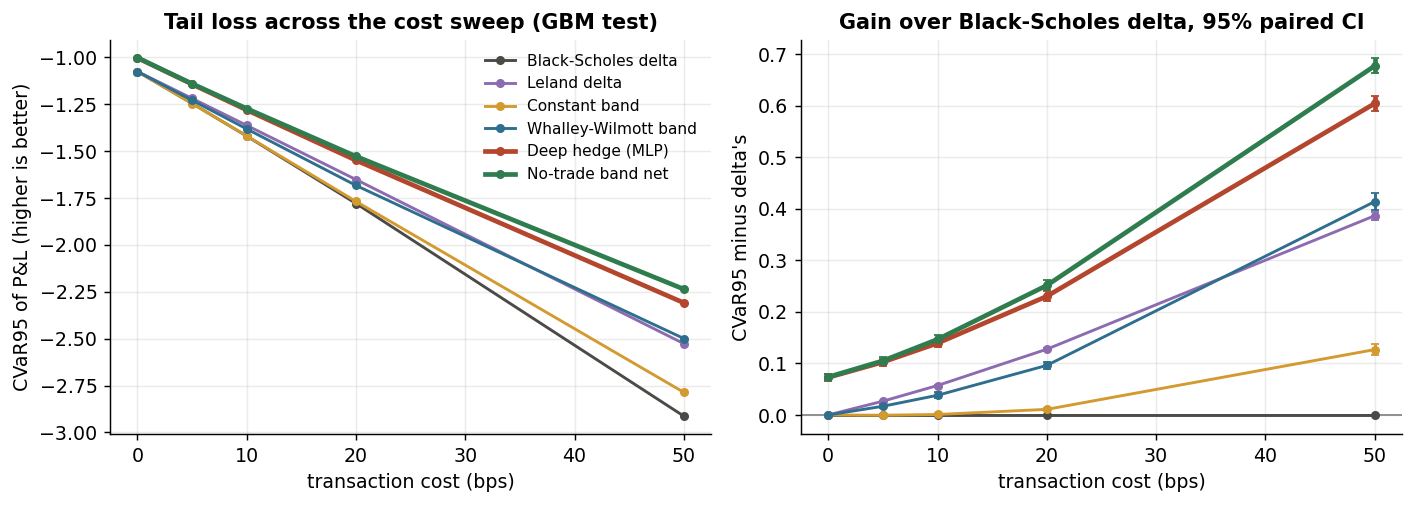

In [11]:
display(Image(os.path.join(RES, 'figures', 'fig_sweep.png')))

**Reading the table.** Both networks beat every rule at 10 bps. Delta is the wrong yardstick for a claim about learning, so the next cell compares each network with the best rule at each cost, using the same paired bootstrap. At every nonzero cost both intervals exclude zero; at 10 bps the networks are ahead of Leland's rule by 6.0% and 6.6% of its tail loss, and at 50 bps the band network is ahead of Whalley-Wilmott by 10.5%.

In [12]:
con = a_all = load('analysis.json')['contrasts']
pd.DataFrame({c: {'best rule': con[f'gbm_{c}']['best_rule'],
                  **{j.split('_')[1] + ' minus best rule (95% CI)': f'[{v[0]:.3f}, {v[1]:.3f}]'
                     for j, v in con[f'gbm_{c}']['minus_best_rule_ci'].items()}}
              for c in (5, 10, 20, 50)}).T

,best rule,mlp minus best rule (95% CI),ntb minus best rule (95% CI)
5,leland,"[0.070, 0.082]","[0.072, 0.085]"
10,leland,"[0.075, 0.089]","[0.083, 0.097]"
20,leland,"[0.095, 0.111]","[0.116, 0.132]"
50,ww|gbm,"[0.176, 0.202]","[0.253, 0.274]"


The MLP trained on a quadratic loss (`gbm_mlpq_c10_s0` above) improves on delta's tail by only 5.7%, against 9.8% for the same network trained on CVaR. Choosing the loss is choosing which mistakes matter. Seeds move the 10 bps result by at most 0.004.

## 7. What did the network learn?

First the control. Trained at zero cost, the network should stay close to Black-Scholes delta, the frictionless answer. With daily rebalancing and a tail objective, delta is not exactly optimal, so a small, smooth deviation is allowed; a large or erratic one would mean our simulation or our gradients were wrong.

In [13]:
a = load('analysis.json')
pd.DataFrame(a['zero_cost']).T.drop(columns='curves', errors='ignore').round(4)

,mean_abs_dev_from_delta,p99_abs_dev,max_abs_dev,cvar_policy,cvar_delta,corr_with_delta
gbm_mlp_c0_s0,0.021,0.0545,0.0704,-1.0026,-1.0753,0.9981
gbm_ntb_c0_s0,0.0215,0.0575,0.0787,-1.0017,-1.0753,0.998


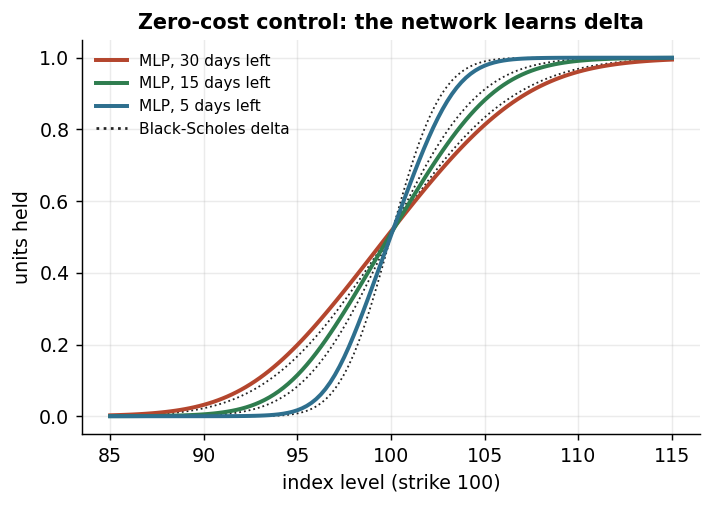

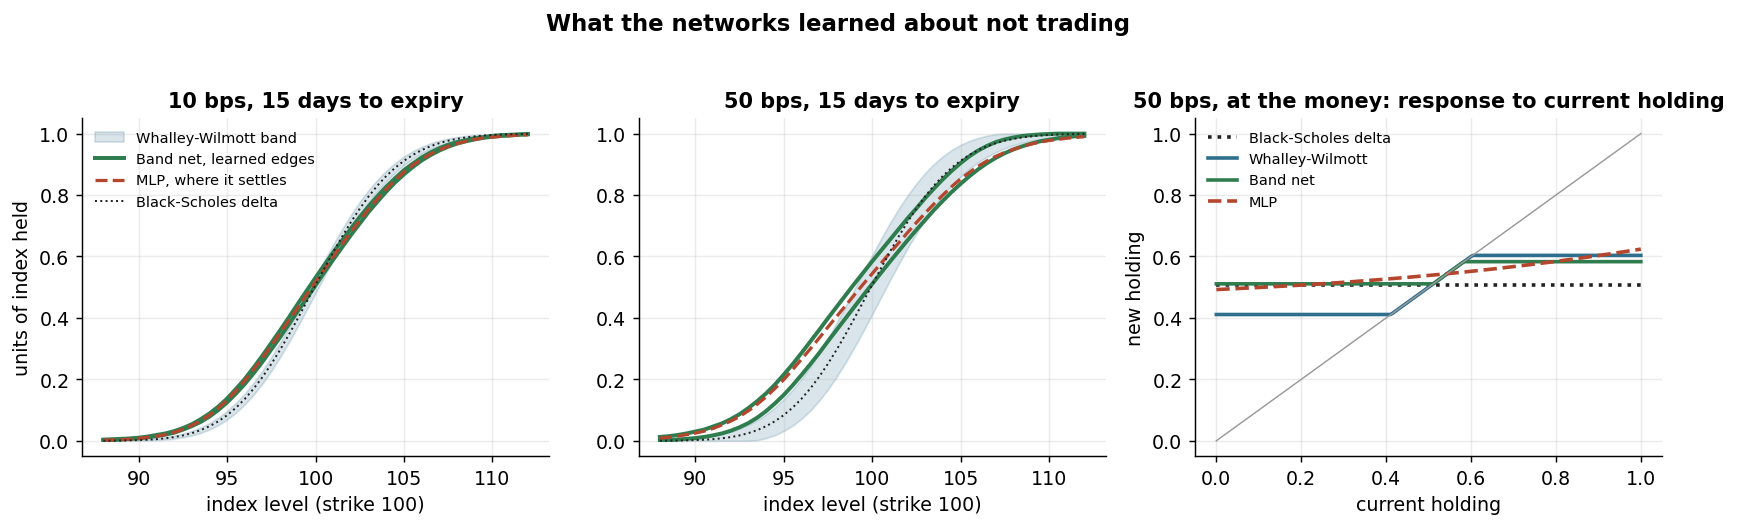

In [14]:
display(Image(os.path.join(RES, 'figures', 'fig_zero.png')))
display(Image(os.path.join(RES, 'figures', 'fig_bands.png')))

To see what the MLP learned about not trading, we ask it, at a fixed index level and time, what it would hold tomorrow for every possible current holding. A hard no-trade band would show up as a stretch where the answer equals the current holding. The MLP does not do that. It trades most of the way to a target and keeps a fraction of the gap, and that fraction (its *inertia*) is what we measure. At zero cost it should be zero.

In [15]:
inert = pd.DataFrame({c: {S: v[S]['slope'] for S in v} for c, v in a['inertia'].items()}).T
inert.index.name = 'cost (bps)'; inert.columns = ['S = 96', 'S = 100', 'S = 104']
inert.round(3)

,S = 96,S = 100,S = 104
cost (bps),,,
0,0.004,-0.009,-0.001
5,0.016,0.010,0.017
10,0.026,0.027,0.036
20,0.039,0.056,0.077
50,0.065,0.134,0.223


Where the MLP *rests* is informative too. We find the volatility at which Black-Scholes delta best matches its resting holdings. A ratio above 1 means it hedges as if volatility were higher than it is: a flatter holding curve that pre-positions for large moves.

In [16]:
ev = pd.DataFrame({c: {f'{30 - int(t)} days left': v[t]['ratio'] for t in v} for c, v in a['effective_vol'].items()}).T
ev.index.name = 'cost (bps)'
ev.round(3)

,30 days left,20 days left,10 days left
cost (bps),,,
0,1.108,1.139,1.182
5,1.146,1.173,1.210
10,1.183,1.206,1.238
20,1.267,1.277,1.297
50,1.510,1.474,1.447


The band network has the band built in, but not its width: that it has to learn. Whalley-Wilmott says the optimal width grows like cost^(1/3), for continuous trading. Here is the fit.

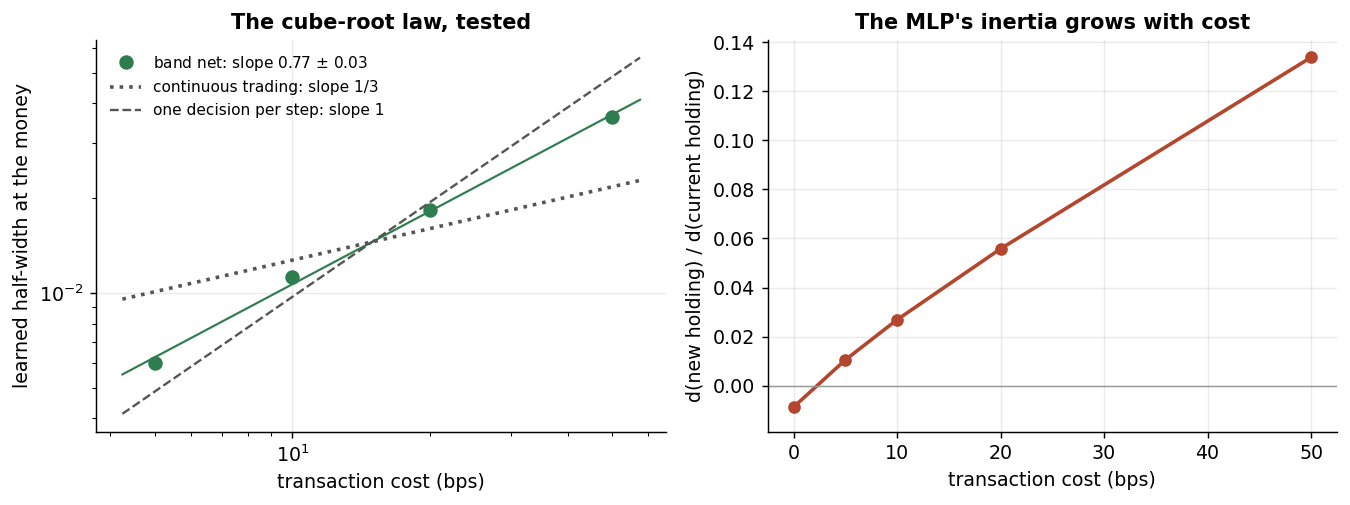

,exponent,exponent_se,r2
ntb,0.7711,0.029,0.9972


In [17]:
display(Image(os.path.join(RES, 'figures', 'fig_scaling.png')))
pd.DataFrame({k: {kk: v[kk] for kk in ('exponent', 'exponent_se', 'r2')} for k, v in a['band_scaling'].items()}).T

**The exponent is 0.77, not 1/3.** Our first suspicion was the network, so the next cell refits the two rules whose widths were tuned on validation separately at each cost, with no network involved. They also grow faster than the cube root.

In [18]:
br = a['band_regime']
pd.Series({'band network exponent': a['band_scaling']['ntb']['exponent'],
           'tuned constant band exponent': br['band_exponent'],
           'tuned Whalley-Wilmott exponent': br['ww_exponent'],
           "one day's move in delta at the money": br['one_day_delta_move'],
           'band network half-width at 50 bps': a['band_scaling']['ntb']['points'][-1][1]}).round(3)

band network exponent                   0.771
tuned constant band exponent            0.534
tuned Whalley-Wilmott exponent          0.652
one day's move in delta at the money    0.103
band network half-width at 50 bps       0.036
dtype: float64

The cube-root argument assumes the holding drifts smoothly into the edge of the band, which needs continuous trading. With one decision a day, delta moves further in a day than the whole band is wide, so the edge is crossed by jumps and the choice is made step by step: keep a gap $x$ and carry risk of order $x^2$ for a day, or pay $k|x|$ to close it. That threshold grows like $k$ itself. The measured exponents sit between the continuous-time $1/3$ and the one-step $1$.

**What the MLP's volatility inflation buys.** The MLP rests near delta computed at 1.14 times the true volatility even at zero cost. Hedging at a higher volatility costs a fixed amount on every path and pays back $\tfrac12(\hat\sigma^2-\sigma^2)\int S^2\Gamma_{\hat\sigma}\,dt$, which is large on paths that stay near the strike, exactly where daily rebalancing leaks most. The next cell (validation set only) scores delta at a scaled volatility, and Leland's rule with its volatility scaled by the MLP's zero-cost factor, next to the MLP itself.

In [19]:
ex_ = a['explain_mlp']
display(pd.Series(ex_['zero_cost_delta_at_c'], name='zero cost: CVaR of delta at sigma x c').round(4))
pd.DataFrame(ex_['by_cost']).T.round(4)

1.00   -1.0802
1.05   -1.0461
1.10   -1.0287
1.15   -1.0273
1.20   -1.0393
1.30   -1.0930
1.45   -1.2275
Name: zero cost: CVaR of delta at sigma x c, dtype: float64

,delta,leland,leland_c0,mlp,share_explained
0,-1.0802,-1.0802,-1.0264,-1.0114,0.7829
5,-1.2509,-1.2248,-1.1680,-1.1542,0.8574
10,-1.4256,-1.3697,-1.3107,-1.2938,0.8721
20,-1.7853,-1.6602,-1.5975,-1.5644,0.8500
50,-2.9152,-2.5383,-2.4693,-2.3278,0.7592


The rule recovers 78% of the MLP's gain over delta at zero cost, 87% at 10 bps and 76% at 50 bps. What it misses grows with cost and is the inertia measured above. The cost part of the inflation grows linearly in the cost, like Leland's, but hardly depends on the level of volatility, where Leland's falls like $1/\sigma$ (`a['explain_mlp']['leland_scaling']`): Leland's direction, not Leland's formula.

## 8. Real markets, 2019 onward

Now the part that matters most and that we could not tune on. Every strategy, with every parameter frozen, on every NIFTY and S&P option sold from 1 January 2019. Neighbouring windows share 29 of their 30 days, so intervals come from a moving-block bootstrap with 30-day blocks.

NIFTY50 - 1910 episodes


,CVaR95,CI,vs delta,CI of diff,mean,sd,fees,trades
strategy,,,,,,,,
unhedged,-9.6346,"[-10.918, -7.941]",-6.5481,"[-8.203, -4.652]",-0.8486,3.4012,0.0000,0.0000
bs_delta,-3.0865,"[-4.030, -2.082]",0.0000,"[0.000, 0.000]",-0.1883,1.1317,0.2766,27.6539
leland,-2.9916,"[-3.923, -2.023]",0.0949,"[0.046, 0.133]",-0.1865,1.1189,0.2701,27.9382
band,-3.1020,"[-4.070, -2.091]",-0.0155,"[-0.060, 0.025]",-0.1875,1.1430,0.2654,17.6832
ww,-3.0458,"[-3.989, -2.135]",0.0407,"[-0.051, 0.136]",-0.1825,1.1343,0.2352,22.2267
gbm_mlp_c10_s0,-2.8335,"[-3.687, -1.932]",0.2530,"[0.095, 0.371]",-0.1752,1.1126,0.2578,28.1869
gbm_ntb_c10_s0,-2.8570,"[-3.763, -1.953]",0.2295,"[0.086, 0.324]",-0.1755,1.1227,0.2440,25.4314
hes_NIFTY50_mlprv_c10_s0,-2.5891,"[-3.383, -1.770]",0.4974,"[0.201, 0.767]",-0.1888,1.1024,0.2284,28.7770
hes_NIFTY50_ntbrv_c10_s0,-2.6664,"[-3.535, -1.788]",0.4201,"[0.166, 0.627]",-0.1952,1.1109,0.2134,24.2628


SP500 - 1949 episodes


,CVaR95,CI,vs delta,CI of diff,mean,sd,fees,trades
strategy,,,,,,,,
unhedged,-8.7317,"[-10.458, -6.835]",-6.0155,"[-7.488, -4.400]",-0.7954,3.1052,0.0000,0.0000
bs_delta,-2.7162,"[-3.694, -1.782]",0.0000,"[0.000, 0.000]",-0.1612,1.2392,0.2867,28.0103
leland,-2.6709,"[-3.701, -1.682]",0.0452,"[-0.026, 0.109]",-0.1565,1.2317,0.2806,28.2945
band,-2.6879,"[-3.642, -1.773]",0.0282,"[0.001, 0.057]",-0.1482,1.2377,0.2743,17.4058
ww,-2.6333,"[-3.621, -1.689]",0.0828,"[-0.017, 0.154]",-0.1175,1.2258,0.2449,22.4797
gbm_mlp_c10_s0,-2.6675,"[-3.773, -1.622]",0.0486,"[-0.143, 0.225]",-0.1402,1.2436,0.2678,28.5090
gbm_ntb_c10_s0,-2.6433,"[-3.744, -1.590]",0.0729,"[-0.111, 0.250]",-0.1242,1.2410,0.2530,25.3643
hes_SP500_mlprv_c10_s0,-2.4161,"[-3.359, -1.522]",0.3001,"[0.121, 0.425]",-0.1884,1.1730,0.2305,29.0493
hes_SP500_ntbrv_c10_s0,-2.3811,"[-3.283, -1.509]",0.3351,"[0.151, 0.482]",-0.1767,1.1545,0.2162,24.7137


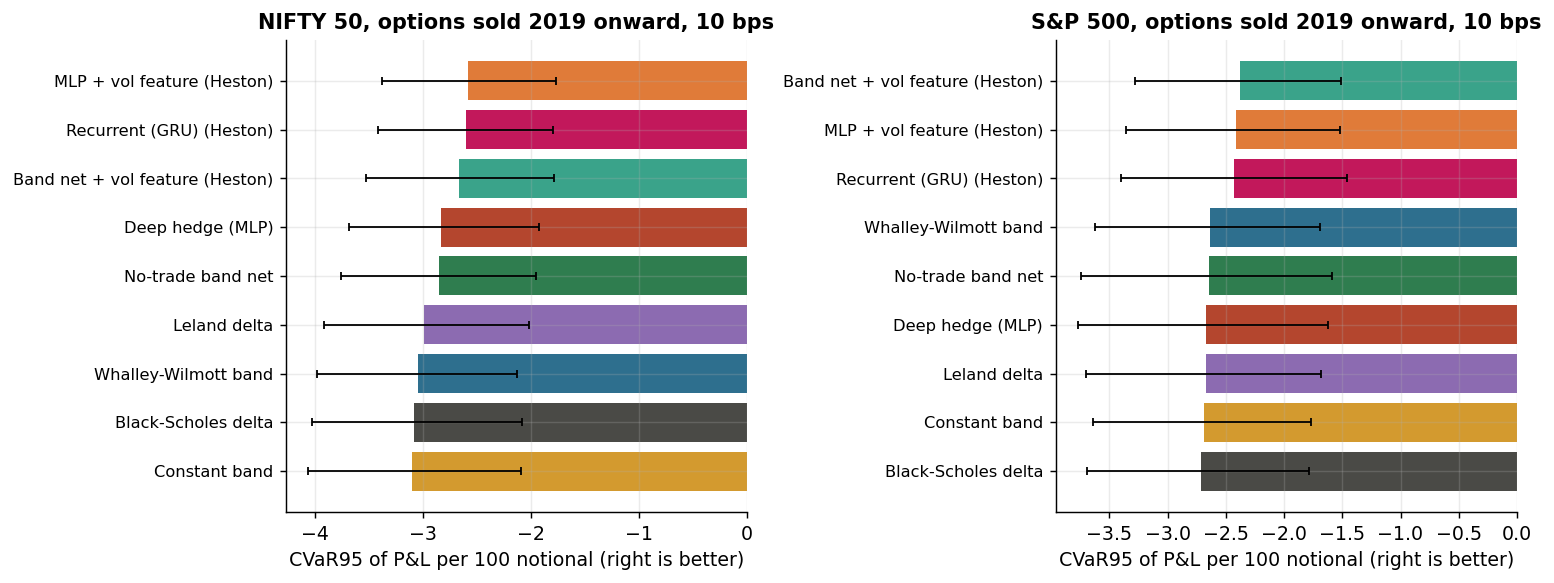

In [20]:
for idx in ('NIFTY50', 'SP500'):
    print(idx, '-', m['real'][idx]['test_2019_on|n_windows'], 'episodes')
    display(table(m['real'][idx]['test_2019_on|gbm_tuned']))
display(Image(os.path.join(RES, 'figures', 'fig_real.png')))

In [21]:
def ladder(idx):
    rows = {}
    worlds = {'GBM sim': m['gbm']['10'], 'Heston sim': m['heston'][idx],
              'real, calibration era': m['real'][idx]['calib_era_pre2019|gbm_tuned'],
              'real, 2019 on': m['real'][idx]['test_2019_on|gbm_tuned']}
    for k in worlds['real, 2019 on']:
        rows[k] = {w: (v[k]['cvar95'] if k in v else np.nan) for w, v in worlds.items()}
    return pd.DataFrame(rows).T.round(3)
for idx in ('NIFTY50', 'SP500'):
    print(idx); display(ladder(idx))

NIFTY50


,GBM sim,Heston sim,"real, calibration era","real, 2019 on"
unhedged,-13.371,-12.248,-15.426,-9.635
bs_delta,-1.420,-2.809,-2.654,-3.086
leland,-1.363,-2.711,-2.633,-2.992
band,-1.419,-2.788,-2.618,-3.102
ww,-1.382,-2.706,-2.684,-3.046
gbm_mlp_c10_s0,-1.281,-2.526,-2.701,-2.834
gbm_ntb_c10_s0,-1.273,-2.516,-2.704,-2.857
hes_NIFTY50_mlprv_c10_s0,NaN,-2.316,-3.099,-2.589
hes_NIFTY50_ntbrv_c10_s0,NaN,-2.311,-3.092,-2.666
hes_NIFTY50_gru_c10_s0,NaN,-2.319,-3.102,-2.603


SP500


,GBM sim,Heston sim,"real, calibration era","real, 2019 on"
unhedged,-13.371,-7.721,-7.245,-8.732
bs_delta,-1.420,-2.518,-2.486,-2.716
leland,-1.363,-2.414,-2.436,-2.671
band,-1.419,-2.495,-2.448,-2.688
ww,-1.382,-2.407,-2.416,-2.633
gbm_mlp_c10_s0,-1.281,-2.285,-2.427,-2.668
gbm_ntb_c10_s0,-1.273,-2.274,-2.411,-2.643
hes_SP500_mlprv_c10_s0,NaN,-2.037,-2.200,-2.416
hes_SP500_ntbrv_c10_s0,NaN,-2.024,-2.191,-2.381
hes_SP500_gru_c10_s0,NaN,-1.991,-2.145,-2.427


**What survives.** Networks trained on the calibrated Heston simulator cut delta's tail loss by 14% to 16% on NIFTY and 11% to 12% on the S&P, every interval excluding zero. The same architectures trained on GBM gain 8% and 2%, the second indistinguishable from zero: the simulator a network learns in shows up in how it trades real markets. Against the best rule, picked by its score on this very test set (which flatters it), the margin is smaller and mostly not significant:

In [22]:
for idx in ('NIFTY50', 'SP500'):
    c = con[f'real_{idx}']
    print(idx, '- best rule:', c['best_rule'], round(c['best_rule_cvar'], 3))
    display(pd.DataFrame(c['minus_best_rule_ci'], index=['2.5%', '97.5%']).T.round(3))

NIFTY50 - best rule: ww|heston -2.905


,2.5%,97.5%
gbm_mlp_c10_s0,-0.205,0.326
gbm_ntb_c10_s0,-0.215,0.296
hes_NIFTY50_mlprv_c10_s0,-0.015,0.536
hes_NIFTY50_ntbrv_c10_s0,-0.067,0.484
hes_NIFTY50_gru_c10_s0,0.027,0.495


SP500 - best rule: ww|heston -2.584


,2.5%,97.5%
gbm_mlp_c10_s0,-0.320,0.181
gbm_ntb_c10_s0,-0.289,0.193
hes_SP500_mlprv_c10_s0,-0.022,0.360
hes_SP500_ntbrv_c10_s0,0.036,0.364
hes_SP500_gru_c10_s0,-0.019,0.355


In the ladder above, delta's tail in the Heston worlds sits close to its tail in the real calibration years, which is what the horizon calibration was for. On NIFTY's calibration era the Heston-trained networks trail delta; section 9 traces that to one day.

## 9. Where the losses come from

To first order a hedged option loses money when realised volatility beats the quote. Every dot below is one real test episode.

In [23]:
rg = a['regimes']; e = rg['edges']
names = ['quietest', 'quiet', 'middle', 'rough', 'roughest']
pd.DataFrame({k: [r['mean'] for r in v] for k, v in rg['strategies'].items()},
             index=[f'{names[g]} ({e[g]:.2f} to {e[g+1]:.2f})' for g in range(5)]).round(3)

,bs_delta,ww,gbm_mlp_c10_s0,gbm_ntb_c10_s0
quietest (0.52 to 0.88),0.158,0.196,0.147,0.162
quiet (0.88 to 0.96),-0.086,-0.043,-0.079,-0.063
middle (0.96 to 1.02),-0.254,-0.206,-0.234,-0.217
rough (1.02 to 1.10),-0.434,-0.385,-0.398,-0.383
roughest (1.10 to 1.60),-0.750,-0.697,-0.696,-0.681


That table splits the 100,000 simulated test paths into fifths by how much realised volatility exceeded the quote, and shows each strategy's mean P&L inside each fifth. It tells us *where* a strategy wins: on quiet paths (saving fees) or on rough ones (protecting the tail).

Now the real data.

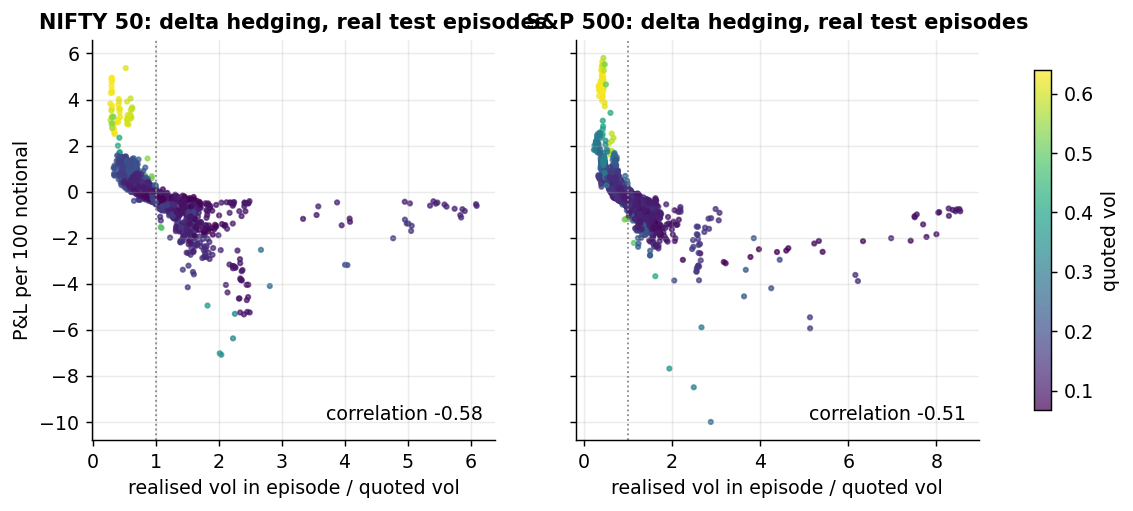

,date,pnl,hedge_error,fee,sigma_imp,rv,vol_ratio,move_pct
0,2020-03-18,-7.082,-6.635,0.447,0.328,0.670,2.044,9.471
1,2020-03-19,-7.019,-6.601,0.418,0.330,0.666,2.019,11.322
2,2020-03-17,-6.371,-5.884,0.487,0.311,0.692,2.230,2.660
3,2024-04-29,-5.329,-4.797,0.532,0.105,0.251,2.404,3.001
4,2020-03-16,-5.305,-4.821,0.484,0.308,0.696,2.259,1.045
5,2020-03-09,-10.000,-9.459,0.541,0.280,0.806,2.883,-0.364
6,2020-03-11,-8.496,-7.946,0.550,0.313,0.782,2.496,2.058
7,2020-03-12,-7.682,-7.217,0.465,0.372,0.722,1.943,14.355
8,2020-02-28,-5.936,-5.679,0.257,0.166,0.851,5.135,-6.519
9,2020-03-10,-5.893,-5.567,0.327,0.298,0.796,2.672,-2.877


In [24]:
display(Image(os.path.join(RES, 'figures', 'fig_volscatter.png')))
w = a['errors']['NIFTY50']['strategies']['bs_delta']['worst'][:5] + a['errors']['SP500']['strategies']['bs_delta']['worst'][:5]
pd.DataFrame(w)[['date', 'pnl', 'hedge_error', 'fee', 'sigma_imp', 'rv', 'vol_ratio', 'move_pct']].round(3)

**The worst episodes are the same for every strategy:** options sold in early March 2020. On NIFTY, delta's worst episodes outside 2020 were sold in late April 2024 and run through 4 June 2024, the general election result, when the index fell about 6%. On the S&P the Heston-trained GRU's worst loss is 6.40 against delta's 10.00; the gain is concentrated where it matters.

**The one day the simulator never showed the networks.** The next cell looks at NIFTY's calibration era, where the Heston-trained networks trail delta.

In [25]:
ce = a['calib_era']
display(pd.DataFrame(ce['worst_years']).fillna(0).astype(int).T)
print('largest one-day move in the data:', ce['largest_move'])
ce['jump_window']

,2007,2008,2009,2010,2011,2013,2014,2015,2016
bs_delta,4,40,22,14,22,18,6,5,3
hes_NIFTY50_mlprv_c10_s0,9,65,46,1,1,9,0,1,2
hes_NIFTY50_gru_c10_s0,7,62,46,1,1,14,0,1,2
gbm_mlp_c10_s0,4,50,24,11,15,16,0,11,3


largest one-day move in the data: {'date': '2009-05-18', 'log_return': 0.16334315490680673}


{'sold': '2009-04-29',
 'day_before': '2009-05-15',
 'delta_held': 0.7353823849866223,
 'net_held': 0.6453911066055298,
 'index_move': 18.75386833884086}

Most of the networks' worst windows were sold in 2008 and 2009 (83%, against 46% for delta), and the very worst contain 18 May 2009, the first trading day after the general election result, when NIFTY rose 18%. The day before, the network held 0.65 of the index where delta held 0.74: the flatter hedge that helps everywhere else left it short of an in-the-money option that jumped, at a cost of about 1.69 per 100 notional. Heston prices move continuously and practically never jump like that, so the networks never learned to fear it. Jumps are the first thing we would add to the simulator.

The full discussion of limitations and the interactive versions of every figure are on the project website.